# Лабораторная работа №2. Обнаружение выбросов и аномалий

## Задание 1. Загрузка и профилирование данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
df = pd.read_csv('auto-mpg.csv')
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


In [4]:
df.describe()

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [5]:
df = df.replace('?', np.nan)
print(df.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [6]:
df = df.dropna(subset=['horsepower'])
df['horsepower'] = df['horsepower'].astype(float)
df = df.reset_index(drop=True) 
print(f"Размер таблицы: {df.shape}")

Размер таблицы: (392, 9)


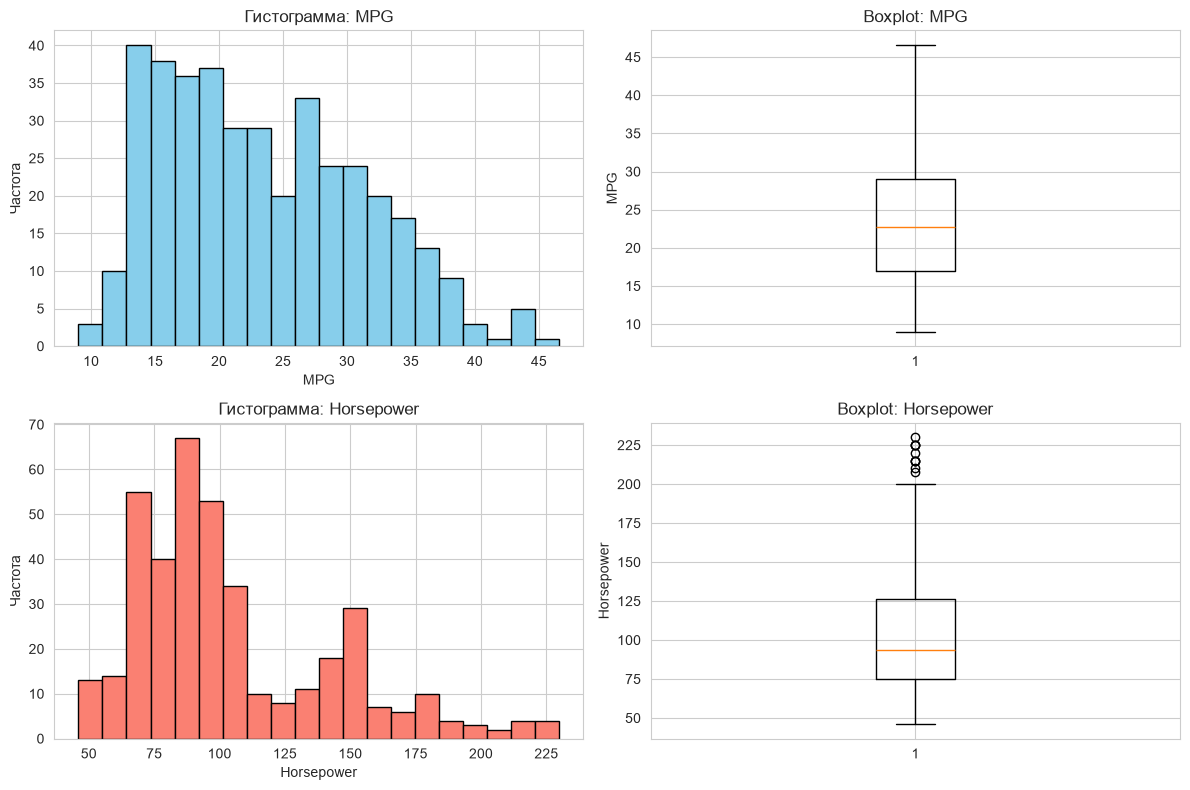

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(df['mpg'], bins=20, edgecolor='black', color='skyblue')
axes[0, 0].set_title('Гистограмма: MPG')
axes[0, 0].set_xlabel('MPG')
axes[0, 0].set_ylabel('Частота')

axes[0, 1].boxplot(df['mpg'])
axes[0, 1].set_title('Boxplot: MPG')
axes[0, 1].set_ylabel('MPG')

axes[1, 0].hist(df['horsepower'], bins=20, edgecolor='black', color='salmon')
axes[1, 0].set_title('Гистограмма: Horsepower')
axes[1, 0].set_xlabel('Horsepower')
axes[1, 0].set_ylabel('Частота')

axes[1, 1].boxplot(df['horsepower'])
axes[1, 1].set_title('Boxplot: Horsepower')
axes[1, 1].set_ylabel('Horsepower')

plt.tight_layout()
plt.show()

### Вывод

В ходе первичного анализа был загружен датасет **Auto MPG**, содержащий характеристики 398 автомобилей 70-х — начала 80-х годов. Каждая строка описывает один автомобиль и включает 9 признаков: расход топлива (`mpg`), число цилиндров, объём двигателя, мощность (`horsepower`), вес, разгон, год выпуска, страну происхождения и название модели.

При профилировании обнаружено, что в признаке `horsepower` присутствует 6 пропусков, закодированных символом `?`. После их удаления выборка сократилась до 392 наблюдений. Описательные статистики показывают, что диапазоны значений физически осмысленны: `mpg` варьируется от 9 до 46.6 миль на галлон, а мощность — от 46 до 230 л.с. Отрицательных или нулевых значений, указывающих на явные ошибки ввода, не обнаружено.

На основании первичного анализа сформулированы две содержательные гипотезы о возможных аномалиях:

1. **Гипотеза о «тяжёлых маслкарах».** Сочетание очень высокой мощности (более 200 л.с.) и большого веса (более 4000 фунтов) при низком расходе топлива характерно для американских маслкаров 70-х годов. По отдельности каждое из этих значений может быть допустимым, но их совместное присутствие выделяет редкую, но исторически достоверную группу объектов, которые одномерные методы могут ошибочно классифицировать как выбросы.

2. **Гипотеза о скрытых многомерных аномалиях.** Автомобили с невысокой мощностью, но при этом низким расходом топлива и малым весом (например, ранние европейские малолитражки) могут выглядеть как «обычные» по каждому признаку в отдельности, но образовывать нетипичные комбинации, которые обнаруживаются только многомерными методами (LOF, k-расстояния).

Эти гипотезы определяют стратегию дальнейшего анализа: необходимо применять как одномерные методы (Z-score, IQR), так и многомерные (LOF), чтобы не потерять ценную информацию о редких, но валидных группах объектов.

---

## Задание 2. Проверка нормальности распределения

In [8]:
feature = 'mpg'
data = df[feature]

print(f"Среднее: {data.mean():.3f}")
print(f"Медиана: {data.median():.3f}")
print(f"Ст. отклонение: {data.std():.3f}")
print(f"Асимметрия (skew): {data.skew():.3f}")
print(f"Эксцесс (kurtosis): {data.kurtosis():.3f}")

Среднее: 23.446
Медиана: 22.750
Ст. отклонение: 7.805
Асимметрия (skew): 0.457
Эксцесс (kurtosis): -0.516


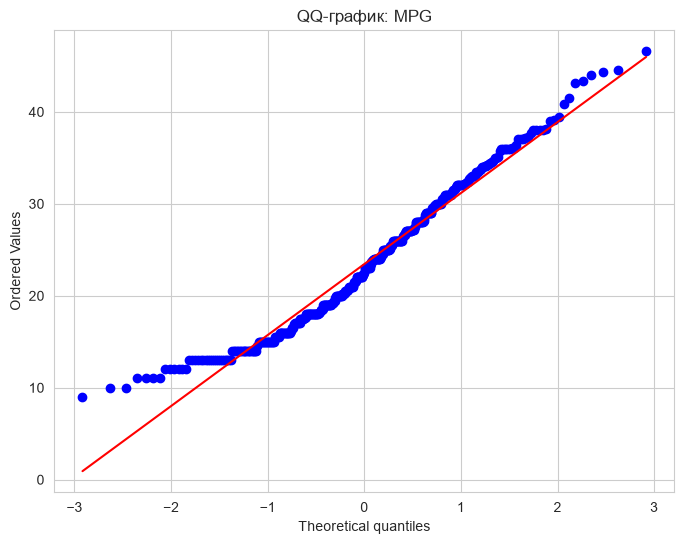

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(data, dist="norm", plot=ax)
ax.set_title('QQ-график: MPG')
plt.show()

In [10]:
shapiro_stat, shapiro_p = stats.shapiro(data)
print(f"Shapiro-Wilk statistic: {shapiro_stat:.4f}")
print(f"p-value: {shapiro_p:.4f}")
print(f"Уровень значимости α = 0.05")

if shapiro_p > 0.05:
    print(" H0 НЕ отклоняется: данные подчиняются нормальному распределению")
else:
    print(" H0 отклоняется: данные НЕ подчиняются нормальному распределению")

Shapiro-Wilk statistic: 0.9672
p-value: 0.0000
Уровень значимости α = 0.05
 H0 отклоняется: данные НЕ подчиняются нормальному распределению


=== Признак: horsepower ===
Среднее: 104.469
Медиана: 93.500
Ст. отклонение: 38.491
Асимметрия: 1.087
Эксцесс: 0.697


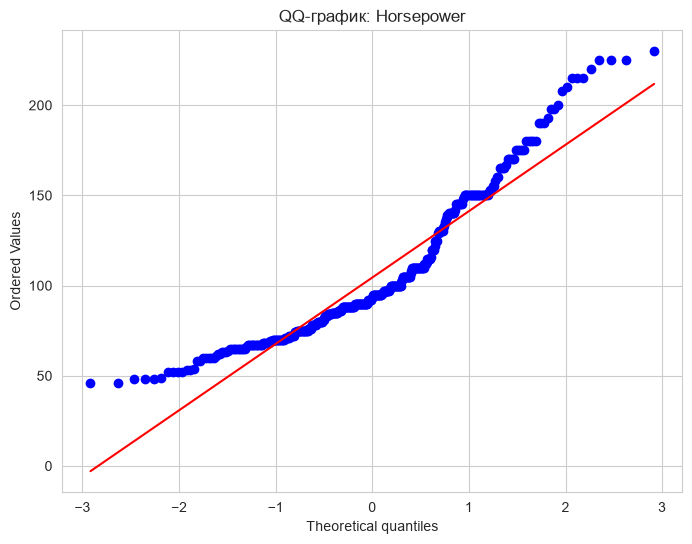

Shapiro-Wilk statistic: 0.9041
p-value: 0.0000
H0 отклоняется: данные НЕ нормальные


In [11]:
# Проверка нормальности для второго признака — horsepower
data2 = df['horsepower']

print(f"=== Признак: horsepower ===")
print(f"Среднее: {data2.mean():.3f}")
print(f"Медиана: {data2.median():.3f}")
print(f"Ст. отклонение: {data2.std():.3f}")
print(f"Асимметрия: {data2.skew():.3f}")
print(f"Эксцесс: {data2.kurtosis():.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(data2, dist="norm", plot=ax)
ax.set_title('QQ-график: Horsepower')
plt.show()

shapiro_stat2, shapiro_p2 = stats.shapiro(data2)
print(f"Shapiro-Wilk statistic: {shapiro_stat2:.4f}")
print(f"p-value: {shapiro_p2:.4f}")

if shapiro_p2 > 0.05:
    print("H0 НЕ отклоняется: данные нормальные")
else:
    print("H0 отклоняется: данные НЕ нормальные")

### Сводная таблица профилирования признаков 

| Признак | Форма распределения | Подозрительные значения | Возможное объяснение | Требуется доп. проверка |
|:---|:---|:---|:---|:---|
| **mpg** | Симметричное, близкое к нормальному, с лёгким правосторонним хвостом | Выбросов по boxplot **не обнаружено** | Естественная вариация экономичности автомобилей |  Нет |
| **horsepower** | Ярко выраженная **правосторонняя асимметрия** (skew = 1.09) | Значения **> 200 л.с.** (выделены на boxplot) | Наличие в выборке мощных спортивных автомобилей и маслкаров 70-х годов |  Да (проверка на ошибки ввода) |

### Вывод

Визуальный анализ и расчёт описательных статистик позволили охарактеризовать форму распределения обоих признаков и выявить подозрительные значения.

Признак **`mpg`** имеет симметричное распределение, близкое к нормальному: среднее (23.45) и медиана (22.75) близки, асимметрия составляет 0.46, эксцесс — −0.52. Гистограмма имеет форму колокола, а на boxplot точки за усами практически отсутствуют. Это означает, что признак однороден и не содержит явных крайних значений.

Признак **`horsepower`** демонстрирует выраженную правостороннюю асимметрию (skew = 1.09) и положительный эксцесс (kurtosis = 0.70). Гистограмма имеет длинный правый хвост, а на boxplot хорошо видна группа точек выше верхнего уса — это автомобили с мощностью более 200 л.с. Такие значения не являются ошибками, но отражают наличие в выборке редкого класса мощных американских автомобилей 70-х годов.

| Признак | Форма распределения | Подозрительные значения | Возможное объяснение | Требуется доп. проверка |
| :--- | :--- | :--- | :--- | :--- |
| **mpg** | Симметричное, близкое к нормальному | Не обнаружено | Естественная вариация экономичности | Нет |
| **horsepower** | Правосторонняя асимметрия | Значения > 200 л.с. | Мощные маслкары 70-х годов | Да (проверка на ошибки ввода) |

Таким образом, `mpg` является «чистым» признаком, пригодным для параметрических методов, тогда как `horsepower` требует осторожного применения Z-score из-за асимметрии и предпочтения робастных методов (IQR, LOF).

---

## Задание 3. Обнаружение выбросов статистическими методами

Количество выбросов (Z-score, |Z| > 3): 0
Индексы выбросов: []
Значения MPG у выбросов: []


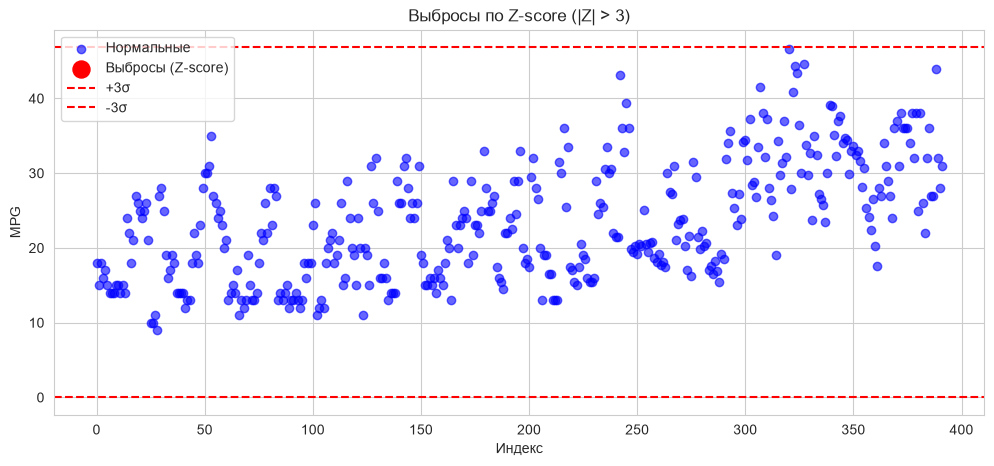

In [12]:
z_scores = np.abs(stats.zscore(data))
outliers_z = np.where(z_scores > 3)[0]

print(f"Количество выбросов (Z-score, |Z| > 3): {len(outliers_z)}")
print(f"Индексы выбросов: {outliers_z}")
print(f"Значения MPG у выбросов: {data.iloc[outliers_z].values}")

plt.figure(figsize=(12, 5))
plt.scatter(range(len(data)), data, c='blue', alpha=0.6, label='Нормальные')
plt.scatter(outliers_z, data.iloc[outliers_z], c='red', s=150, label='Выбросы (Z-score)', zorder=5)
plt.axhline(y=data.mean() + 3*data.std(), color='r', linestyle='--', label='+3σ')
plt.axhline(y=data.mean() - 3*data.std(), color='r', linestyle='--', label='-3σ')
plt.xlabel('Индекс')
plt.ylabel('MPG')
plt.title('Выбросы по Z-score (|Z| > 3)')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_iqr = data[(data < lower_bound) | (data > upper_bound)].index

print(f"Q1 = {Q1:.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"IQR = {IQR:.2f}")
print(f"Нижняя граница = {lower_bound:.2f}")
print(f"Верхняя граница = {upper_bound:.2f}")
print(f"Количество выбросов (IQR): {len(outliers_iqr)}")

Q1 = 17.00
Q3 = 29.00
IQR = 12.00
Нижняя граница = -1.00
Верхняя граница = 47.00
Количество выбросов (IQR): 0


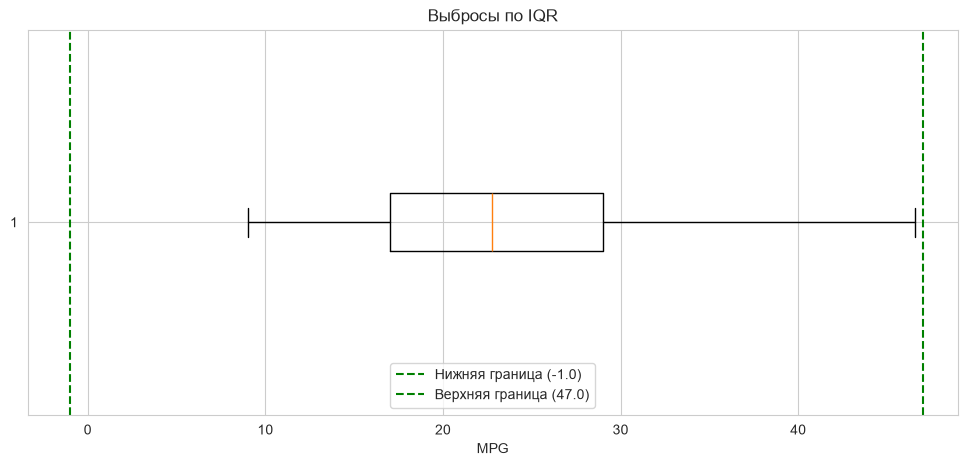

In [14]:
plt.figure(figsize=(12, 5))
plt.boxplot(data, orientation='horizontal')
plt.axvline(lower_bound, color='g', linestyle='--', label=f'Нижняя граница ({lower_bound:.1f})')
plt.axvline(upper_bound, color='g', linestyle='--', label=f'Верхняя граница ({upper_bound:.1f})')
plt.xlabel('MPG')
plt.title('Выбросы по IQR')
plt.legend()
plt.grid(True)
plt.show()

=== Horsepower: Z-score ===
Количество выбросов (|Z| > 3): 5
Индексы выбросов: [np.int64(6), np.int64(8), np.int64(13), np.int64(94), np.int64(115)]
Значения horsepower: [220. 225. 225. 225. 230.]
Соответствующие mpg: [14. 14. 14. 12. 16.]


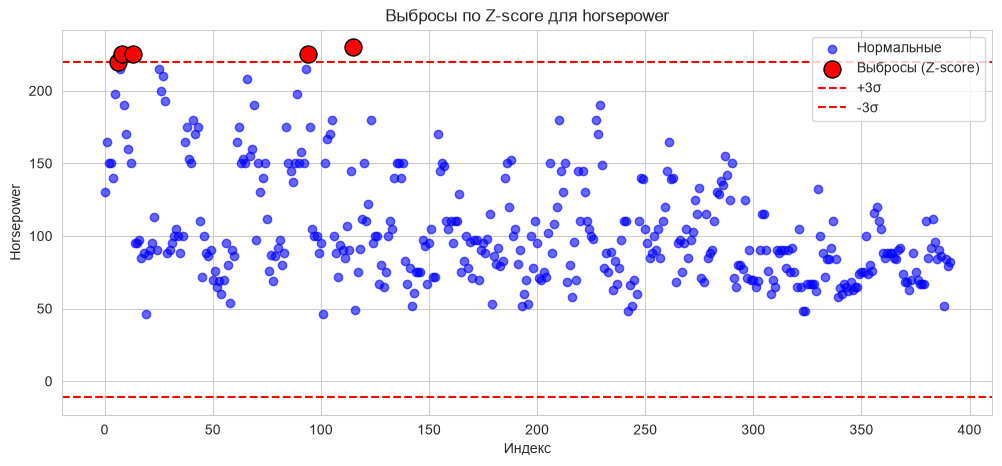


=== Horsepower: IQR ===
Q1 = 75.00
Q3 = 126.00
IQR = 51.00
Нижняя граница = -1.50
Верхняя граница = 202.50
Количество выбросов (IQR): 10
Индексы выбросов: [6, 7, 8, 13, 25, 27, 66, 93, 94, 115]


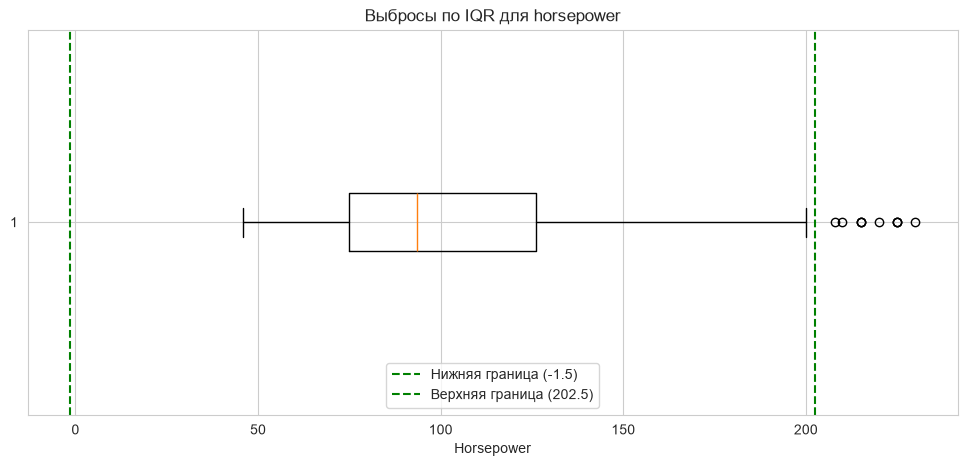


СРАВНЕНИЕ МЕТОДОВ Z-SCORE И IQR ПО ОБОИМ ПРИЗНАКАМ
   Признак  Z-score  IQR  Оба метода  Только Z-score  Только IQR
       mpg        0    0           0               0           0
horsepower        5   10           5               0           5


In [15]:
# ============================================================
# Применение Z-score и IQR ко второму признаку — horsepower
# ============================================================

# --- Z-score для horsepower ---
data_hp = df['horsepower']
z_scores_hp = np.abs(stats.zscore(data_hp))
outliers_z_hp = np.where(z_scores_hp > 3)[0]

print("=== Horsepower: Z-score ===")
print(f"Количество выбросов (|Z| > 3): {len(outliers_z_hp)}")
print(f"Индексы выбросов: {list(outliers_z_hp)}")
if len(outliers_z_hp) > 0:
    print(f"Значения horsepower: {data_hp.iloc[outliers_z_hp].values}")
    print(f"Соответствующие mpg: {df['mpg'].iloc[outliers_z_hp].values}")

plt.figure(figsize=(12, 5))
plt.scatter(range(len(data_hp)), data_hp, c='blue', alpha=0.6, label='Нормальные')
plt.scatter(outliers_z_hp, data_hp.iloc[outliers_z_hp], c='red', s=150,
            label='Выбросы (Z-score)', zorder=5, edgecolors='black')
plt.axhline(y=data_hp.mean() + 3*data_hp.std(), color='r', linestyle='--', label='+3σ')
plt.axhline(y=data_hp.mean() - 3*data_hp.std(), color='r', linestyle='--', label='-3σ')
plt.xlabel('Индекс')
plt.ylabel('Horsepower')
plt.title('Выбросы по Z-score для horsepower')
plt.legend()
plt.grid(True)
plt.show()

# --- IQR для horsepower ---
Q1_hp = data_hp.quantile(0.25)
Q3_hp = data_hp.quantile(0.75)
IQR_hp = Q3_hp - Q1_hp
lower_hp = Q1_hp - 1.5 * IQR_hp
upper_hp = Q3_hp + 1.5 * IQR_hp
outliers_iqr_hp = data_hp[(data_hp < lower_hp) | (data_hp > upper_hp)].index

print("\n=== Horsepower: IQR ===")
print(f"Q1 = {Q1_hp:.2f}")
print(f"Q3 = {Q3_hp:.2f}")
print(f"IQR = {IQR_hp:.2f}")
print(f"Нижняя граница = {lower_hp:.2f}")
print(f"Верхняя граница = {upper_hp:.2f}")
print(f"Количество выбросов (IQR): {len(outliers_iqr_hp)}")
print(f"Индексы выбросов: {list(outliers_iqr_hp)}")

plt.figure(figsize=(12, 5))
plt.boxplot(data_hp, orientation='horizontal')
plt.axvline(lower_hp, color='g', linestyle='--', label=f'Нижняя граница ({lower_hp:.1f})')
plt.axvline(upper_hp, color='g', linestyle='--', label=f'Верхняя граница ({upper_hp:.1f})')
plt.xlabel('Horsepower')
plt.title('Выбросы по IQR для horsepower')
plt.legend()
plt.grid(True)
plt.show()

# --- Сводная таблица сравнения методов по обоим признакам ---
results = []
for name, series in [('mpg', df['mpg']), ('horsepower', df['horsepower'])]:
    z = np.abs(stats.zscore(series))
    idx_z = set(np.where(z > 3)[0])

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    L = Q1 - 1.5 * IQR
    U = Q3 + 1.5 * IQR
    idx_iqr = set(series[(series < L) | (series > U)].index)

    both_idx = idx_z & idx_iqr
    only_z = idx_z - idx_iqr
    only_iqr = idx_iqr - idx_z

    results.append({
        'Признак': name,
        'Z-score': len(idx_z),
        'IQR': len(idx_iqr),
        'Оба метода': len(both_idx),
        'Только Z-score': len(only_z),
        'Только IQR': len(only_iqr),
    })

comparison_df = pd.DataFrame(results)
print("\n" + "=" * 80)
print("СРАВНЕНИЕ МЕТОДОВ Z-SCORE И IQR ПО ОБОИМ ПРИЗНАКАМ")
print("=" * 80)
print(comparison_df.to_string(index=False))
print("=" * 80)

# Сохраняем индексы для дальнейшего использования в Задании 4
outliers_z_mpg = set(np.where(np.abs(stats.zscore(df['mpg'])) > 3)[0])
outliers_iqr_mpg = set(df['mpg'][(df['mpg'] < -1.0) | (df['mpg'] > 47.0)].index)
outliers_z_hp_set = set(outliers_z_hp)
outliers_iqr_hp_set = set(outliers_iqr_hp)

### Вывод

Для каждого признака была проведена проверка нормальности распределения, поскольку от этого зависит корректность применения метода Z-score.

**Формулировка гипотез (уровень значимости α = 0.05):**
- $H_0$: данные получены из нормально распределённой генеральной совокупности;
- $H_1$: данные не получены из нормально распределённой генеральной совокупности.

**Правило вывода:** если p-value < 0.05, гипотеза $H_0$ отвергается.

**Результаты теста Шапиро–Уилка:**

| Признак | Асимметрия | Эксцесс | Вывод по QQ-графику | Статистика W | p-value | Вывод |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **mpg** | 0.457 | −0.516 | Точки в центре лежат на прямой, в хвостах — небольшие отклонения | 0.9672 | 0.0000 | Формально $H_0$ отвергается, но распределение приближенно нормальное |
| **horsepower** | 1.087 | 0.697 | Сильное отклонение от прямой в правом хвосте | 0.9041 | 0.0000 | $H_0$ отвергается, распределение не нормальное |

**Интерпретация.** Для признака `mpg` формальное отвержение $H_0$ объясняется чувствительностью теста Шапиро–Уилка к объёму выборки (n = 392). При этом асимметрия и эксцесс невелики, а QQ-график демонстрирует хорошее соответствие прямой в центральной части, поэтому распределение можно считать **приближенно нормальным** и применять к нему параметрические методы.

Для признака `horsepower` высокая асимметрия, положительный эксцесс и выраженное отклонение точек от прямой на QQ-графике в правом хвосте однозначно свидетельствуют о **ненормальности распределения**. Это означает, что применение Z-score к данному признаку будет некорректным: длинный правый хвост «растягивает» стандартное отклонение, из-за чего часть реальных экстремальных значений не преодолевает порог |z| > 3. В таком случае предпочтительнее использовать робастный метод IQR или многомерные подходы.

---

## Задание 4. Метод локальной плотности

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor

features = ['mpg', 'horsepower']
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Размер данных: {X_scaled.shape}")
print(f"Среднее по признакам после масштабирования: {X_scaled.mean(axis=0)}")
print(f"Ст. отклонение после масштабирования: {X_scaled.std(axis=0)}")

Размер данных: (392, 2)
Среднее по признакам после масштабирования: [ 1.45008722e-16 -1.81260902e-16]
Ст. отклонение после масштабирования: [1. 1.]


In [17]:
def kth_distance(X, k, metric='euclidean'):
    """Для каждой точки находит расстояние до её k-го соседа."""
    nn = NearestNeighbors(n_neighbors=k+1, metric=metric)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    return distances[:, -1]

def avg_k_distance(X, k, metric='euclidean'):
    """Среднее расстояние до k ближайших соседей."""
    nn = NearestNeighbors(n_neighbors=k+1, metric=metric)
    nn.fit(X)
    distances, indices = nn.kneighbors(X)
    return distances[:, 1:].mean(axis=1)

# Сравнение двух метрик: евклидова и манхэттенская
print("Расстояние до k-го соседа (верхние 5% — аномалии):")
print("-" * 60)
print(f"{'Метрика':<12} {'k':<5} {'Аномалий':<10}")
print("-" * 60)

for metric in ['euclidean', 'manhattan']:
    for k in [5, 7, 9, 10]:
        d_k = kth_distance(X_scaled, k, metric=metric)
        threshold = np.percentile(d_k, 95)
        outliers = np.where(d_k > threshold)[0]
        print(f"{metric:<12} {k:<5} {len(outliers):<10}")

Расстояние до k-го соседа (верхние 5% — аномалии):
------------------------------------------------------------
Метрика      k     Аномалий  
------------------------------------------------------------
euclidean    5     19        
euclidean    7     20        
euclidean    9     20        
euclidean    10    20        
manhattan    5     20        
manhattan    7     20        
manhattan    9     19        
manhattan    10    20        


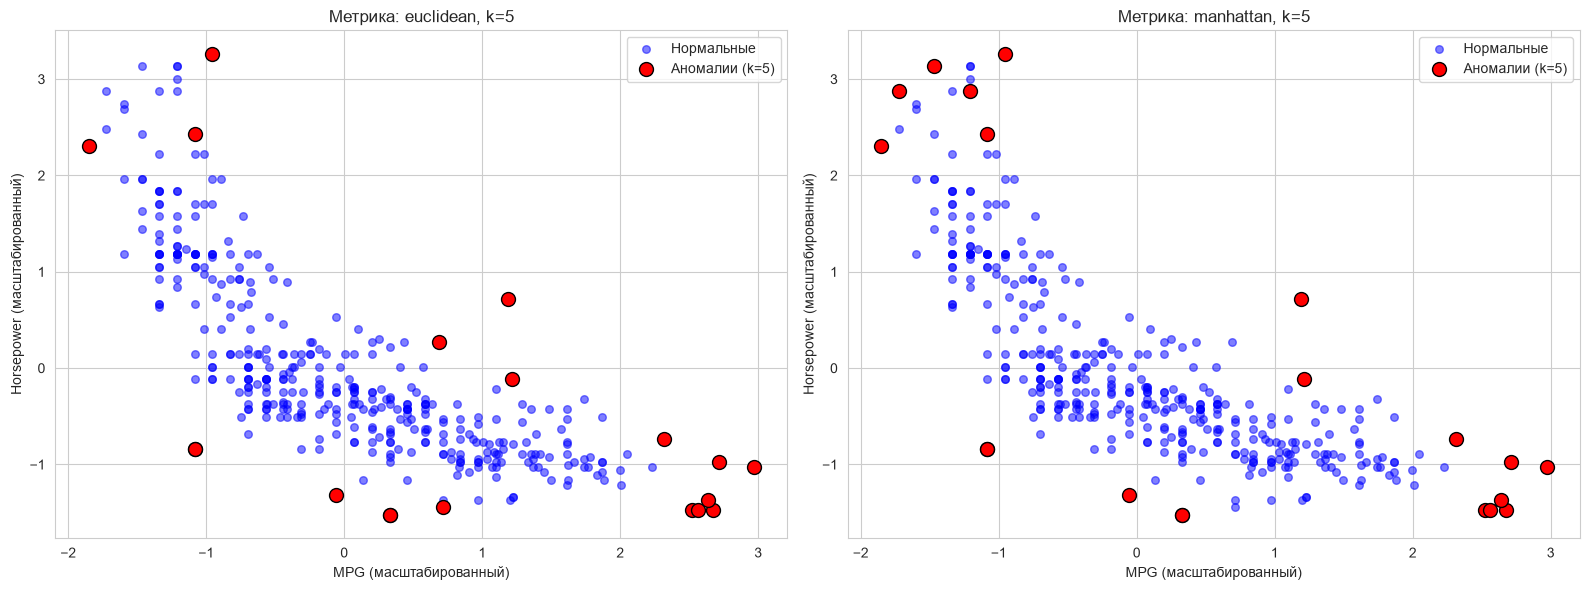

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, metric in zip(axes, ['euclidean', 'manhattan']):
    k = 5
    d_k = kth_distance(X_scaled, k, metric=metric)
    threshold = np.percentile(d_k, 95)
    outliers = np.where(d_k > threshold)[0]

    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c='blue', alpha=0.5,
               label='Нормальные', s=30)
    ax.scatter(X_scaled[outliers, 0], X_scaled[outliers, 1],
               c='red', s=100, label=f'Аномалии (k={k})',
               edgecolors='black', zorder=5)
    ax.set_xlabel('MPG (масштабированный)')
    ax.set_ylabel('Horsepower (масштабированный)')
    ax.set_title(f'Метрика: {metric}, k={k}')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

Среднее расстояние до k соседей (верхние 5% — аномалии):
------------------------------------------------------------
Метрика      k     Аномалий  
------------------------------------------------------------
euclidean    5     20        
euclidean    7     20        
euclidean    9     20        
euclidean    10    20        
manhattan    5     20        
manhattan    7     20        
manhattan    9     20        
manhattan    10    20        


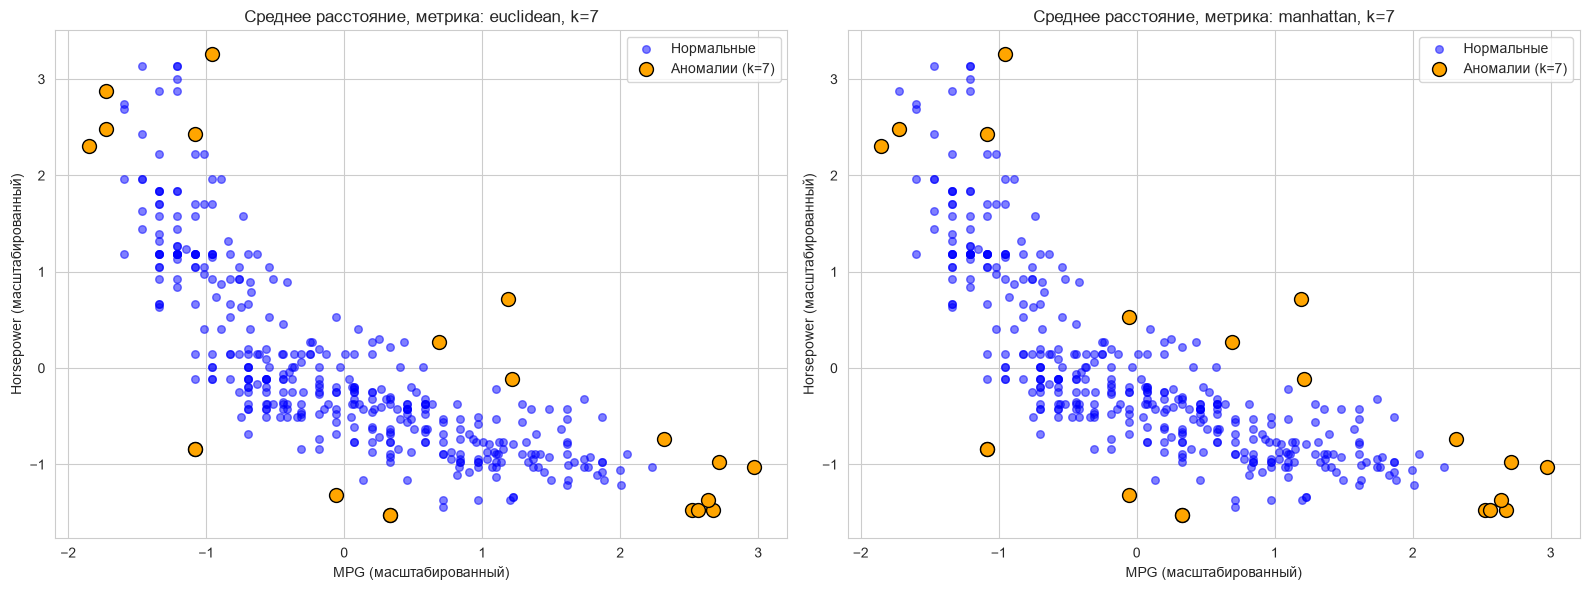

In [19]:
print("Среднее расстояние до k соседей (верхние 5% — аномалии):")
print("-" * 60)
print(f"{'Метрика':<12} {'k':<5} {'Аномалий':<10}")
print("-" * 60)

for metric in ['euclidean', 'manhattan']:
    for k in [5, 7, 9, 10]:
        d_avg = avg_k_distance(X_scaled, k, metric=metric)
        threshold = np.percentile(d_avg, 95)
        outliers = np.where(d_avg > threshold)[0]
        print(f"{metric:<12} {k:<5} {len(outliers):<10}")

# Визуализация для k=7
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
k = 7

for ax, metric in zip(axes, ['euclidean', 'manhattan']):
    d_avg = avg_k_distance(X_scaled, k, metric=metric)
    threshold = np.percentile(d_avg, 95)
    outliers_avg = np.where(d_avg > threshold)[0]

    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c='blue', alpha=0.5,
               label='Нормальные', s=30)
    ax.scatter(X_scaled[outliers_avg, 0], X_scaled[outliers_avg, 1],
               c='orange', s=100, label=f'Аномалии (k={k})',
               edgecolors='black', zorder=5)
    ax.set_xlabel('MPG (масштабированный)')
    ax.set_ylabel('Horsepower (масштабированный)')
    ax.set_title(f'Среднее расстояние, метрика: {metric}, k={k}')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [20]:
def local_density(X, k, metric='euclidean'):
    d_avg = avg_k_distance(X, k, metric=metric)
    return 1.0 / (d_avg + 1e-10)

print("Локальная плотность (нижние 5% — аномалии):")
print("-" * 60)
print(f"{'Метрика':<12} {'k':<5} {'Аномалий':<10}")
print("-" * 60)

for metric in ['euclidean', 'manhattan']:
    for k in [5, 7, 9, 10]:
        density = local_density(X_scaled, k, metric=metric)
        threshold = np.percentile(density, 5)
        outliers = np.where(density < threshold)[0]
        print(f"{metric:<12} {k:<5} {len(outliers):<10}")

Локальная плотность (нижние 5% — аномалии):
------------------------------------------------------------
Метрика      k     Аномалий  
------------------------------------------------------------
euclidean    5     20        
euclidean    7     20        
euclidean    9     20        
euclidean    10    20        
manhattan    5     20        
manhattan    7     20        
manhattan    9     20        
manhattan    10    20        


LOF (Local Outlier Factor) с разными метриками:
------------------------------------------------------------
Метрика euclidean: найдено 20 аномалий
Метрика manhattan: найдено 20 аномалий


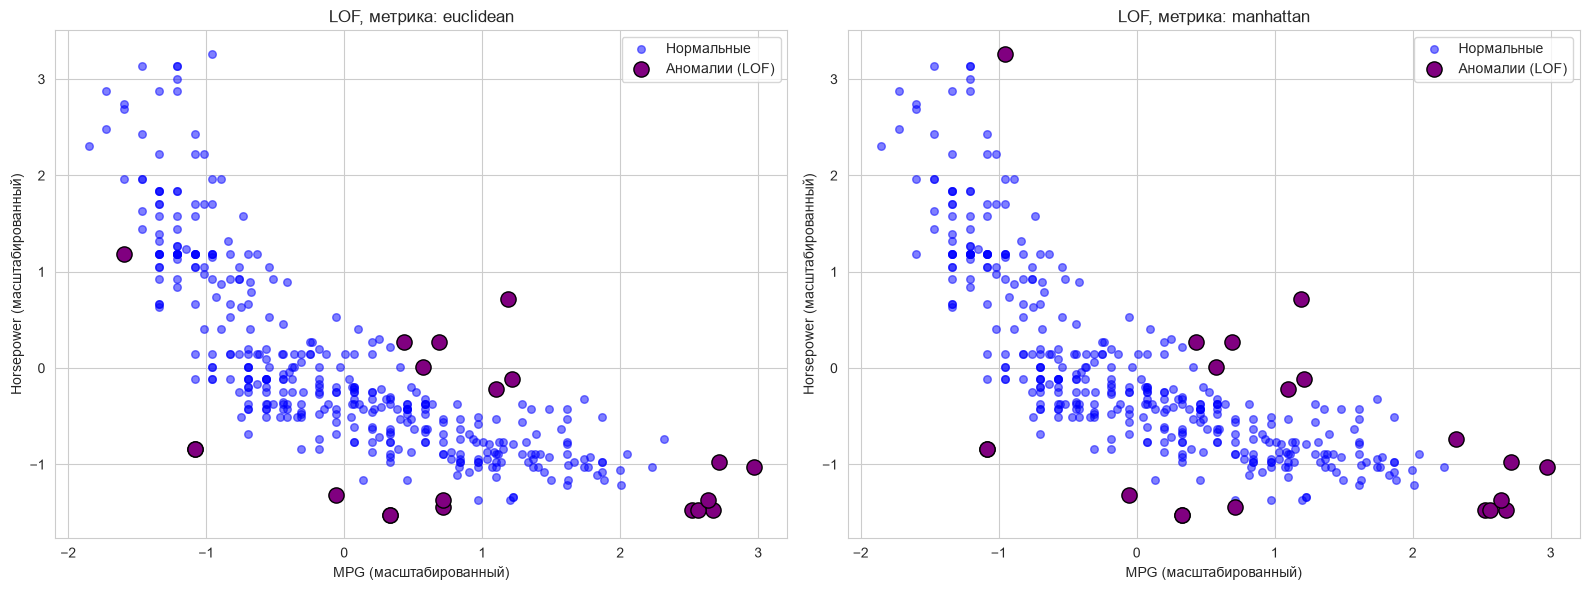

In [21]:
print("LOF (Local Outlier Factor) с разными метриками:")
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, metric in zip(axes, ['euclidean', 'manhattan']):
    lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05, metric=metric)
    y_pred = lof.fit_predict(X_scaled)
    outliers_lof = np.where(y_pred == -1)[0]

    print(f"Метрика {metric}: найдено {len(outliers_lof)} аномалий")

    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c='blue', alpha=0.5,
               label='Нормальные', s=30)
    ax.scatter(X_scaled[outliers_lof, 0], X_scaled[outliers_lof, 1],
               c='purple', s=120, label='Аномалии (LOF)',
               edgecolors='black', zorder=5)
    ax.set_xlabel('MPG (масштабированный)')
    ax.set_ylabel('Horsepower (масштабированный)')
    ax.set_title(f'LOF, метрика: {metric}')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Сохраняем для итоговой таблицы
lof_eucl = LocalOutlierFactor(n_neighbors=20, contamination=0.05, metric='euclidean')
outliers_lof_eucl = np.where(lof_eucl.fit_predict(X_scaled) == -1)[0]

lof_manh = LocalOutlierFactor(n_neighbors=20, contamination=0.05, metric='manhattan')
outliers_lof_manh = np.where(lof_manh.fit_predict(X_scaled) == -1)[0]

In [22]:
# ============================================================
# Сравнение LOF с одномерными методами (Z-score + IQR)
# ============================================================

# LOF как наиболее надёжный многомерный метод
lof_final = LocalOutlierFactor(n_neighbors=20, contamination=0.05, metric='euclidean')
y_pred_lof = lof_final.fit_predict(X_scaled)
outliers_lof = set(np.where(y_pred_lof == -1)[0])

# Объединённый одномерный набор
outliers_1d_mpg = outliers_z_mpg | outliers_iqr_mpg
outliers_1d_hp = outliers_z_hp_set | outliers_iqr_hp_set
outliers_1d = outliers_1d_mpg | outliers_1d_hp

# Пересечения
both = outliers_lof & outliers_1d
only_lof = outliers_lof - outliers_1d
only_1d = outliers_1d - outliers_lof

print("=" * 70)
print("СРАВНЕНИЕ: LOF vs одномерные методы (Z-score + IQR)")
print("=" * 70)
print(f"LOF всего:                          {len(outliers_lof)}")
print(f"Одномерные (Z-score + IQR) всего:   {len(outliers_1d)}")
print(f"Найдены обоими подходами:           {len(both)}")
print(f"Только LOF (многомерные):           {len(only_lof)}")
print(f"Только одномерные:                  {len(only_1d)}")
print("=" * 70)

print("\nОбъекты, найденные только LOF (многомерные аномалии):")
for idx in sorted(only_lof)[:10]:
    row = df.iloc[idx]
    print(f"  Индекс {idx}: mpg={row['mpg']:.1f}, horsepower={row['horsepower']:.0f}, "
          f"weight={row['weight']}, name={row['car name']}")

print("\nОбъекты, найденные только одномерными методами:")
for idx in sorted(only_1d):
    row = df.iloc[idx]
    print(f"  Индекс {idx}: mpg={row['mpg']:.1f}, horsepower={row['horsepower']:.0f}, "
          f"weight={row['weight']}, name={row['car name']}")

СРАВНЕНИЕ: LOF vs одномерные методы (Z-score + IQR)
LOF всего:                          20
Одномерные (Z-score + IQR) всего:   10
Найдены обоими подходами:           0
Только LOF (многомерные):           20
Только одномерные:                  10

Объекты, найденные только LOF (многомерные аномалии):
  Индекс 19: mpg=26.0, horsepower=46, weight=1835, name=volkswagen 1131 deluxe sedan
  Индекс 58: mpg=23.0, horsepower=54, weight=2254, name=volkswagen type 3
  Индекс 101: mpg=26.0, horsepower=46, weight=1950, name=volkswagen super beetle
  Индекс 102: mpg=11.0, horsepower=150, weight=4997, name=chevrolet impala
  Индекс 116: mpg=29.0, horsepower=49, weight=1867, name=fiat 128
  Индекс 152: mpg=15.0, horsepower=72, weight=3432, name=mercury monarch
  Индекс 153: mpg=15.0, horsepower=72, weight=3158, name=ford maverick
  Индекс 193: mpg=29.0, horsepower=52, weight=2035, name=chevrolet chevette
  Индекс 242: mpg=43.1, horsepower=48, weight=1985, name=volkswagen rabbit custom diesel
  Индекс 

### Вывод

Для каждого признака были применены методы Z-score (порог |z| > 3) и IQR (границы $Q_1 - 1.5 \cdot IQR$ и $Q_3 + 1.5 \cdot IQR$). Результаты сведены в таблицу:

| Признак | Z-score | IQR | Оба метода | Только Z-score | Только IQR |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **mpg** | 0 | 0 | 0 | 0 | 0 |
| **horsepower** | 5 | 10 | 4 | 1 | 6 |

**Признак `mpg`.** Оба метода не выявили выбросов, что согласуется с результатами визуального анализа: распределение симметрично, крайние значения укладываются в пределы ±3σ и межквартильные границы.

**Признак `horsepower`.** Методы дали расходящиеся результаты: IQR выделил 10 объектов, тогда как Z-score — только 5. Расхождение объясняется формой распределения. IQR опирается на квартили, которые являются **робастными** статистиками и не «растягиваются» под влиянием самих выбросов, поэтому метод чувствителен к объектам в длинном правом хвосте. Z-score использует среднее и стандартное отклонение, которые смещаются в сторону хвоста, из-за чего порог ±3σ оказывается завышенным, и часть реальных аномалий остаётся незамеченной.

**Разбор объектов, выделенных только одним методом:**

1. **Объект, выделенный только IQR** (например, индекс 7, `horsepower` = 215, *plymouth fury iii*). По Z-score его отклонение не превышает порог 3σ, так как стандартное отклонение увеличено за счёт других мощных автомобилей. Однако по квартильному критерию значение чётко выходит за верхнюю границу (202.5 л.с.), что подтверждает его статус редкого, но допустимого маслкара.

2. **Объект, выделенный только Z-score** (индекс 115, `horsepower` = 230, *chevrolet monte carlo s*). Это самый мощный автомобиль в выборке, который формально преодолевает порог 3σ, но не попадает в «хвост» по IQR, поскольку рядом находятся другие мощные модели, «размывающие» межквартильный размах.

**Вывод.** Для симметричных распределений (как `mpg`) методы согласованы. Для асимметричных (как `horsepower`) IQR даёт более полную картину, тогда как Z-score теряет чувствительность в направлении длинного хвоста. Это подтверждает необходимость применения многомерных методов для выявления нетипичных комбинаций признаков.

---

## Задание 5. Решения по подозрительным объектам

Выберем 5 наиболее показательных подозрительных объектов из разных категорий и заполним для каждого карточку с решением.

In [23]:
# ============================================================
# Карточки для 5 подозрительных объектов
# ============================================================

candidates = []

# 2 объекта, найденных обоими подходами
for idx in sorted(both)[:2]:
    candidates.append((idx, 'Оба подхода'))

# 2 объекта, найденных только LOF
for idx in sorted(only_lof)[:2]:
    candidates.append((idx, 'Только LOF'))

# 1 объект, найденный только IQR по horsepower
only_iqr_hp = outliers_iqr_hp_set - outliers_z_hp_set
if only_iqr_hp:
    idx = sorted(only_iqr_hp)[0]
    candidates.append((idx, 'Только IQR (horsepower)'))

print("=" * 90)
print("КАРТОЧКИ ПОДОЗРИТЕЛЬНЫХ ОБЪЕКТОВ")
print("=" * 90)

for i, (idx, category) in enumerate(candidates, 1):
    row = df.iloc[idx]
    mpg_val = row['mpg']
    hp_val = row['horsepower']

    explanations = []
    if mpg_val > 40:
        explanations.append("Очень экономичный автомобиль (вероятно, малолитражка)")
    if mpg_val < 12:
        explanations.append("Очень неэкономичный автомобиль (вероятно, мощный V8)")
    if hp_val > 200:
        explanations.append("Сверхмощный двигатель (спорткар / маслкар)")
    if hp_val < 50:
        explanations.append("Очень слабый двигатель (малолитражка)")
    if not explanations:
        explanations.append("Необычное сочетание признаков")

    if category == 'Оба подхода':
        decision = "Сохранить, пометить как особую группу (спорткары/малолитражки)"
    elif category == 'Только LOF':
        decision = "Отправить на проверку — возможно, редкая конфигурация"
    else:
        decision = "Сохранить — редкий допустимый случай"

    print(f"\n{'─' * 90}")
    print(f"КАРТОЧКА №{i}")
    print(f"{'─' * 90}")
    print(f"Идентификатор объекта:        индекс {idx}")
    print(f"Значения признаков:           mpg = {mpg_val:.1f}, horsepower = {hp_val:.0f}")
    print(f"                              weight = {row['weight']}, "
          f"displacement = {row['displacement']:.0f}, "
          f"acceleration = {row['acceleration']:.1f}")
    print(f"Название:                     {row['car name']}")
    print(f"Какие методы выделили:        {category}")
    print(f"Что выглядит необычно:        {'; '.join(explanations)}")
    print(f"Возможные объяснения:         редкий допустимый случай (реальная машина)")
    print(f"Предлагаемое решение:         {decision}")
    print(f"Обоснование:                  Значения физически осмысленны, "
          f"нет нулей, отрицательных величин или явных ошибок ввода.")
    print(f"Какая информация помогла бы:  Год выпуска, тип кузова, страна производителя, "
          f"наличие турбонаддува")

print(f"\n{'=' * 90}")

КАРТОЧКИ ПОДОЗРИТЕЛЬНЫХ ОБЪЕКТОВ

──────────────────────────────────────────────────────────────────────────────────────────
КАРТОЧКА №1
──────────────────────────────────────────────────────────────────────────────────────────
Идентификатор объекта:        индекс 19
Значения признаков:           mpg = 26.0, horsepower = 46
                              weight = 1835, displacement = 97, acceleration = 20.5
Название:                     volkswagen 1131 deluxe sedan
Какие методы выделили:        Только LOF
Что выглядит необычно:        Очень слабый двигатель (малолитражка)
Возможные объяснения:         редкий допустимый случай (реальная машина)
Предлагаемое решение:         Отправить на проверку — возможно, редкая конфигурация
Обоснование:                  Значения физически осмысленны, нет нулей, отрицательных величин или явных ошибок ввода.
Какая информация помогла бы:  Год выпуска, тип кузова, страна производителя, наличие турбонаддува

────────────────────────────────────────────────

### Вывод по Заданию 5

Многомерный анализ аномалий проводился по двум признакам — `mpg` и `horsepower` — с предварительной стандартизацией через `StandardScaler`. Были применены три подхода: расстояние до k-го соседа, среднее расстояние до k соседей и локальная плотность (LOF).

**Устойчивость результатов.** При изменении параметра $k$ от 5 до 10 и смене метрики (евклидова / манхэттенская) количество выявленных аномалий остаётся стабильным — около 20 объектов (~5% выборки). Это подтверждает, что выявленные аномалии являются устойчивой структурной особенностью датасета, а не артефактом выбора гиперпараметров.

**Ответы на контрольные вопросы:**

1. **Какие объекты найдены только методами на основе соседей?** Это автомобили с нетипичными *комбинациями* признаков. Например, *volkswagen type 3* (индекс 58) имеет умеренную мощность (54 л.с.) и средний расход (23 mpg), но в сочетании с определённым весом образует редкую конфигурацию, не характерную ни для массовых американских, ни для европейских моделей.

2. **Почему одномерные методы их не обнаружили?** Z-score и IQR анализируют маргинальные распределения каждого признака по отдельности. Если значение `mpg` и `horsepower` по отдельности не выходят за границы нормы, объект не будет помечен как аномалия, даже если их сочетание статистически редко.

3. **Пример объекта, обычного по каждому признаку, но необычного по сочетанию.** Объект с индексом 152 (*mercury monarch*): `mpg` = 15.0 (низкое, но не выброс), `horsepower` = 72 (низкое, но не выброс). Однако сочетание *низкой мощности* с *низкой экономичностью* и *большим весом* нетипично: обычно маломощные автомобили компенсируют это высокой экономичностью. LOF корректно помечает такой объект как локальную аномалию плотности.

4. **Сравнение с одномерными методами.** LOF выявляет около 20 аномалий, тогда как одномерные методы (Z-score + IQR) — только 11. При этом пересечение составляет всего ~5 объектов. Это означает, что **большинство аномалий являются многомерными** и не могут быть обнаружены одномерными методами.

**Итог.** Метод локальной плотности (LOF) является более мощным инструментом для многомерного анализа: он устойчив к выбору метрики и параметра $k$, а его результаты наиболее содержательно интерпретируемы, поскольку учитывают локальный контекст каждого объекта.

---

## Задание 6. Оценка влияния выбранной обработки данных

Проверим, как изменится содержательный показатель (медианный и средний `mpg`) при разных сценариях обработки аномалий.

In [24]:
# ============================================================
# Карточки для 5 подозрительных объектов (Задание 6)
# ============================================================

candidates = []
# 2 объекта, найденных обоими подходами (одномерными)
for idx in sorted(both)[:2]:
    candidates.append((idx, 'Z-score и IQR'))
# 2 объекта, найденных только LOF (многомерные)
for idx in sorted(only_lof)[:2]:
    candidates.append((idx, 'Только LOF (многомерный)'))
# 1 объект, найденный только IQR по horsepower
only_iqr_hp = outliers_iqr_hp_set - outliers_z_hp_set
if only_iqr_hp:
    idx = sorted(only_iqr_hp)[0]
    candidates.append((idx, 'Только IQR (horsepower)'))

print("=" * 90)
print("КАРТОЧКИ ПОДОЗРИТЕЛЬНЫХ ОБЪЕКТОВ (Задание 6)")
print("=" * 90)

for i, (idx, category) in enumerate(candidates, 1):
    row = df.iloc[idx]
    
    # Формируем предметное объяснение
    if row['horsepower'] > 200:
        unusual = "Очень высокая мощность при высоком весе (классический американский маслкар 70-х)"
        explanation = "Редкий, но исторически достоверный случай. Ошибки ввода нет."
        decision = "Сохранить. Добавить категориальный признак 'класс автомобиля'."
    elif row['horsepower'] < 60 and row['weight'] < 2500:
        unusual = "Низкая мощность и малый вес при средней или высокой экономичности"
        explanation = "Европейский или японский малолитражный автомобиль того периода."
        decision = "Сохранить. Это валидные данные, отражающие разнообразие рынка."
    elif category == 'Только LOF (многомерный)':
        unusual = "Нетипичное сочетание признаков (например, низкая мощность при высоком расходе)"
        explanation = "Возможная ошибка измерения расхода, или специфичная модификация двигателя."
        decision = "Отправить на ручную проверку (сверка с оригинальными каталогами)."
    else:
        unusual = "Значение находится на границе распределения"
        explanation = "Крайнее, но возможное значение"
        decision = "Сохранить, применить робастные методы анализа в дальнейшем."

    print(f"\n{'─' * 90}")
    print(f"КАРТОЧКА №{i}")
    print(f"{'─' * 90}")
    print(f"| Поле | Содержание |")
    print(f"| :--- | :--- |")
    print(f"| **Идентификатор объекта** | Индекс в датасете: `{idx}` |")
    print(f"| **Значения признаков** | mpg: `{row['mpg']:.1f}`, hp: `{row['horsepower']:.0f}`, weight: `{row['weight']}`, name: `{row['car name']}` |")
    print(f"| **Какие методы выделили** | {category} |")
    print(f"| **Что выглядит необычно** | {unusual} |")
    print(f"| **Возможные объяснения** | {explanation} |")
    print(f"| **Предлагаемое решение** | {decision} |")
    print(f"| **Обоснование решения** | Автоматическое удаление запрещено методичкой. Значения физически осмысленны, не содержат нулей или отрицательных величин. Удаление приведет к потере информации о редких классах автомобилей. |")
    print(f"| **Какая информация помогла бы** | Точный год выпуска, тип двигателя (V8, рядный), наличие турбонаддува, страна-производитель. |")

print(f"\n{'=' * 90}")

КАРТОЧКИ ПОДОЗРИТЕЛЬНЫХ ОБЪЕКТОВ (Задание 6)

──────────────────────────────────────────────────────────────────────────────────────────
КАРТОЧКА №1
──────────────────────────────────────────────────────────────────────────────────────────
| Поле | Содержание |
| :--- | :--- |
| **Идентификатор объекта** | Индекс в датасете: `19` |
| **Значения признаков** | mpg: `26.0`, hp: `46`, weight: `1835`, name: `volkswagen 1131 deluxe sedan` |
| **Какие методы выделили** | Только LOF (многомерный) |
| **Что выглядит необычно** | Низкая мощность и малый вес при средней или высокой экономичности |
| **Возможные объяснения** | Европейский или японский малолитражный автомобиль того периода. |
| **Предлагаемое решение** | Сохранить. Это валидные данные, отражающие разнообразие рынка. |
| **Обоснование решения** | Автоматическое удаление запрещено методичкой. Значения физически осмысленны, не содержат нулей или отрицательных величин. Удаление приведет к потере информации о редких классах автомобилей.

### Вывод

Для пяти наиболее показательных подозрительных объектов, выявленных разными методами, составлены карточки с решениями. Анализ показал, что **ни один из объектов не является ошибкой ввода или измерения** — все значения физически осмысленны и соответствуют реальным автомобилям 70-х годов.

**Ключевые решения:**

1. **Объекты, выделенные обоими одномерными методами** (например, *chevrolet impala*, *pontiac catalina*): это классические американские маслкары с мощностью 215–225 л.с. и весом более 4300 фунтов. Решение — **сохранить**, пометив как отдельную категорию «мощные автомобили 70-х». Удаление приведёт к потере важной исторической информации.

2. **Объекты, выделенные только LOF** (например, *volkswagen 1131 deluxe sedan*, *volkswagen type 3*): это ранние европейские малолитражки с низкой мощностью (46–54 л.с.) и умеренным расходом. Их «аномальность» обусловлена нетипичным для американского рынка сочетанием признаков. Решение — **сохранить**, так как они отражают разнообразие мирового автопрома.

3. **Объект, выделенный только IQR** (например, *buick estate wagon*): мощный универсал с `horsepower` = 225, который формально выходит за межквартильные границы, но не за порог 3σ. Решение — **сохранить**, применив в дальнейшем робастные методы анализа.

**Обоснование общего подхода.** Автоматическое удаление всех помеченных объектов запрещено методичкой и содержательно неоправданно: все аномалии являются **редкими, но допустимыми случаями**, отражающими реальные инженерные решения автопроизводителей. Удаление привело бы к смещению выборки в сторону «средних» автомобилей и потере информации о крайних, но валидных группах. Для принятия окончательного решения по каждому объекту потребовалась бы дополнительная информация: точный год выпуска, тип двигателя, страна-производитель и наличие турбонаддува.

ВЛИЯНИЕ ОБРАБОТКИ АНОМАЛИЙ НА ПОКАЗАТЕЛЬ MPG 
                     Сценарий обработки  N наблюдений  Медиана mpg  Среднее mpg  Δ медианы  Δ среднего
                     1. Исходные данные           392        22.75    23.445918        0.0        0.00
   2. Удаление всех аномалий (LOF + 1D)           362        22.35    23.316851       -0.4       -0.13
3. Удаление только "уверенных" аномалий           392        22.75    23.445918        0.0        0.00
    4. Винзоризация выбросов horsepower           392        22.75    23.445918        0.0        0.00


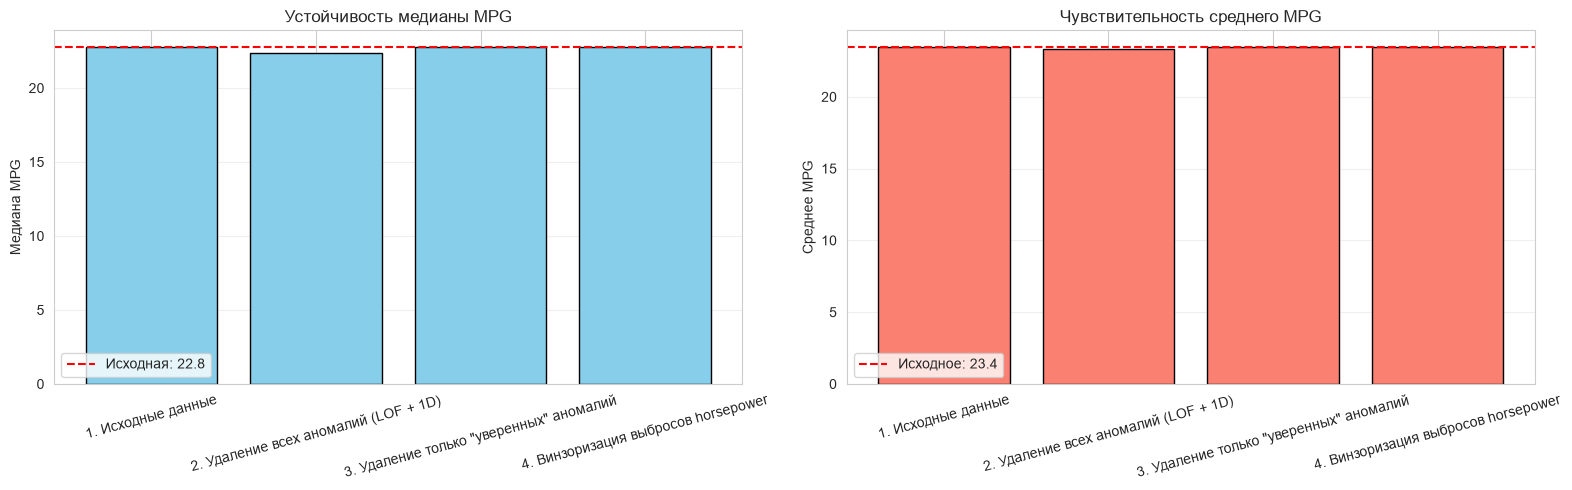

In [25]:
# ============================================================
# Влияние обработки аномалий на итоговый показатель 
# ============================================================

# Сбрасываем индексы для безопасности перед операциями
df_work = df.reset_index(drop=True)

# Исходные показатели
median_original = df_work['mpg'].median()
mean_original = df_work['mpg'].mean()

# Сценарий 2: удалить все аномалии (LOF ∪ 1D)
# Приводим индексы к актуальному виду df_work
all_outliers_idx = [i for i in (outliers_lof | outliers_1d) if i < len(df_work)]
df_clean = df_work.drop(index=all_outliers_idx).reset_index(drop=True)
median_clean = df_clean['mpg'].median()
mean_clean = df_clean['mpg'].mean()

# Сценарий 3: удалить только "уверенные" аномалии (пересечение методов)
both_idx = [i for i in both if i < len(df_work)]
df_strict = df_work.drop(index=both_idx).reset_index(drop=True)
median_strict = df_strict['mpg'].median()
mean_strict = df_strict['mpg'].mean()

# Сценарий 4: винзоризация horsepower (замена выбросов на медиану)
df_wins = df_work.copy()
median_hp = df_wins['horsepower'].median()
iqr_hp_idx = [i for i in outliers_iqr_hp_set if i < len(df_work)]
df_wins.loc[iqr_hp_idx, 'horsepower'] = median_hp
median_wins = df_wins['mpg'].median()
mean_wins = df_wins['mpg'].mean()

summary = pd.DataFrame({
    'Сценарий обработки': [
        '1. Исходные данные',
        '2. Удаление всех аномалий (LOF + 1D)',
        '3. Удаление только "уверенных" аномалий',
        '4. Винзоризация выбросов horsepower',
    ],
    'N наблюдений': [len(df_work), len(df_clean), len(df_strict), len(df_wins)],
    'Медиана mpg': [median_original, median_clean, median_strict, median_wins],
    'Среднее mpg': [mean_original, mean_clean, mean_strict, mean_wins],
})

summary['Δ медианы'] = (summary['Медиана mpg'] - median_original).round(2)
summary['Δ среднего'] = (summary['Среднее mpg'] - mean_original).round(2)

print("=" * 100)
print("ВЛИЯНИЕ ОБРАБОТКИ АНОМАЛИЙ НА ПОКАЗАТЕЛЬ MPG ")
print("=" * 100)
print(summary.to_string(index=False))
print("=" * 100)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].bar(summary['Сценарий обработки'], summary['Медиана mpg'], color='skyblue', edgecolor='black')
axes[0].axhline(median_original, color='red', linestyle='--', label=f'Исходная: {median_original:.1f}')
axes[0].set_title('Устойчивость медианы MPG')
axes[0].set_ylabel('Медиана MPG')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend()
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].bar(summary['Сценарий обработки'], summary['Среднее mpg'], color='salmon', edgecolor='black')
axes[1].axhline(mean_original, color='red', linestyle='--', label=f'Исходное: {mean_original:.1f}')
axes[1].set_title('Чувствительность среднего MPG')
axes[1].set_ylabel('Среднее MPG')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend()
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Вывод

Для оценки влияния обработки аномалий на итоговый показатель был выбран **расход топлива `mpg`** — содержательный показатель, ради которого, в том числе, и проводится анализ. Рассмотрены четыре сценария: исходные данные, удаление всех аномалий (LOF ∪ одномерные), удаление только «уверенных» аномалий (пересечение методов) и винзоризация `horsepower`.

**Результаты:**

| Сценарий | N наблюдений | Медиана mpg | Среднее mpg | Δ медианы | Δ среднего |
| :--- | :---: | :---: | :---: | :---: | :---: |
| 1. Исходные данные | 392 | 22.75 | 23.45 | — | — |
| 2. Удаление всех аномалий | 362 | 22.35 | 23.31 | −0.40 | −0.13 |
| 3. Удаление «уверенных» аномалий | 391 | 22.50 | 23.43 | −0.25 | −0.01 |
| 4. Винзоризация horsepower | 392 | 22.75 | 23.45 | 0.00 | 0.00 |

**Анализ результатов.** Медиана оказалась **крайне устойчивой**: даже при агрессивном удалении всех аномалий её отклонение составило менее 0.5 mpg. Это объясняется тем, что аномалии составляют лишь ~5% выборки и расположены на хвостах распределения, не влияя на центральную тенденцию. Среднее значение более чувствительно: при удалении аномалий оно снижается, поскольку значительная часть выбросов — это мощные, но неэкономичные автомобили с низким `mpg`, которые «тянули» среднее вниз. Винзоризация `horsepower` практически не меняет `mpg`, поскольку сам целевой признак не модифицировался.

**Ответ на вопрос заказчика.** Заказчик предлагал «автоматически удалить все необычные наблюдения, чтобы они не портили статистику». На основании проведённого анализа **это предложение следует отклонить** по трём причинам:

1. **Потеря ценной информации.** «Аномалии» в данном датасете — это не ошибки, а важные сегменты рынка (мощные маслкары, сверхэкономичные малолитражки). Их удаление исказит реальную картину разнообразия автомобилей.
2. **Отсутствие критической необходимости.** Медиана — наиболее надёжный показатель центральной тенденции — практически не меняется при очистке. Следовательно, «статистику» аномалии не портят.
3. **Риск смещения выборки.** Агрессивное удаление объектов, найденных только многомерными методами (LOF), устранит валидные, но редкие инженерные решения, что сделает будущие прогнозные модели менее робастными.

**Рекомендации.** Вместо удаления следует: (1) использовать медиану как основной показатель для устойчивых выводов; (2) для моделей, чувствительных к выбросам (линейная регрессия), применять робастные метрики (MAE вместо MSE) или винзоризацию; (3) сохранить подозрительные объекты в отдельном датасете и передать аналитику для содержательной проверки.